# Public health analysis — Child survival

Under-five mortality — the probability that a newborn dies before their fifth birthday, per 1,000 live births — is where the global health divide shows up sharpest. A child born in the wrong country today still faces risks that rich countries left behind two generations ago.

Three views in this notebook:

1. **Regional trends since 1950** — on a log scale, because the declines are multiplicative,
2. **Child survival vs water and sanitation** (WASH),
3. **Child survival vs routine immunization** (DTP3 coverage).

The standing caveat for the last two: these are cross-country **correlations**. WASH access and DTP3 coverage both track the general strength of a health system and the economy behind it; neither scatter is a causal estimate of "what a latrine buys" or "what a vaccine prevents" — vaccine efficacy is what trials are for. More on this in `docs/limitations.md`.

Reads `../data/processed/panel.csv` from [data_wrangling.ipynb](data_wrangling.ipynb).

In [1]:
# Setup block -- same as the other notebooks so each one runs on its own.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D8DEE4", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.labelsize": 10.5, "axes.labelcolor": "#4A5560",
    "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.titlepad": 14, "axes.titlecolor": "#1A2530",
    "legend.frameon": False, "legend.fontsize": 9.5,
    "figure.dpi": 110, "savefig.dpi": 200,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

REGION_COLORS = {
    "Africa": "#EE7733",
    "Asia": "#0077BB",
    "Europe": "#009988",
    "North America": "#33BBEE",
    "South America": "#CC3311",
    "Oceania": "#EE3377",
}
NEUTRAL, NEUTRAL_LIGHT, GRID = "#4A5560", "#9AA7B2", "#E8EDF1"
SOURCE_NOTE = ("Source: Our World in Data (UN WPP 2024, UN IGME 2024, World Bank, "
               "WHO GHO, IHME GBD, Maddison Project). CC BY 4.0.")

def headline(ax, title, subtitle=None):
    ax.set_title(title, loc="left", pad=34 if subtitle else 14)
    if subtitle:
        ax.text(0, 1.045, subtitle, transform=ax.transAxes,
                fontsize=10, color=NEUTRAL, va="bottom")

def clean_axis(ax, grid=True, axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if grid:
        ax.grid(axis=axis, color=GRID, linewidth=0.7)
        ax.set_axisbelow(True)

def save(fig, name, note=SOURCE_NOTE):
    if note:
        fig.text(0.006, 0.008, note, fontsize=7.5, color=NEUTRAL_LIGHT, va="bottom")
        try:
            fig.get_layout_engine().set(rect=(0, 0.042, 1, 0.958))
        except Exception:
            pass
    path = f"../figures/{name}.png"
    fig.savefig(path, dpi=200, facecolor="white")
    plt.show()
    print("saved", path)

def line_end_labels(ax, entries, dx_px=9, min_gap_px=15):
    """Right-edge direct labels with collision avoidance (see global_trends.ipynb)."""
    fig = ax.figure
    fig.canvas.draw()
    pts = [ax.transData.transform((e["x"], e["y"])) for e in entries]
    to_frac = ax.transAxes.inverted()
    order = sorted(range(len(entries)), key=lambda i: pts[i][1])
    ys = [pts[i][1] for i in order]
    for k in range(1, len(ys)):
        if ys[k] - ys[k - 1] < min_gap_px:
            ys[k] = ys[k - 1] + min_gap_px
    for k, idx in enumerate(order):
        e = entries[idx]
        fx, fy = to_frac.transform((pts[idx][0] + dx_px, ys[k]))
        ax.annotate(e["text"], xy=(e["x"], e["y"]), xycoords="data",
                    xytext=(fx, fy), textcoords="axes fraction",
                    fontsize=e.get("fontsize", 9.3),
                    fontweight=e.get("weight", "normal"),
                    color=e["color"], va="center")

def weighted_mean(df, value, weight="population"):
    d = df[[value, weight]].dropna()
    return float(np.average(d[value], weights=d[weight])) if len(d) else np.nan

def regional_series(df, value):
    rows = []
    for (year, region), chunk in df.groupby(["year", "region"]):
        rows.append({"year": year, "region": region,
                     "value": weighted_mean(chunk, value)})
    return pd.DataFrame(rows)

def latest_snapshot(df, value, window=5):
    """Each country's most recent value within `window` years of the
    indicator's own latest year (they don't all publish on the same
    schedule -- anchoring anywhere else silently drops the older series)."""
    el = df.dropna(subset=[value])
    anchor = int(el["year"].max())
    el = el[el["year"].between(anchor - window + 1, anchor)]
    snap = (el.sort_values("year")
              .groupby("country", as_index=False)
              .tail(1)
              .rename(columns={"year": "ref_year", value: "value"}))
    cols = ["country", "iso3", "region", "ref_year", "value"]
    if "population" in snap.columns and value != "population":
        cols.append("population")
    return snap[cols]

def snapshot_multi(df, keys, window=5, min_pop_k=0):
    """One row per country, each indicator at its own latest vintage. With
    min_pop_k set, microstates drop out (volatile statistics; they would
    otherwise dominate the corners of every scatter)."""
    base = df[["country", "iso3", "region"]].drop_duplicates()
    for key in keys:
        s = latest_snapshot(df, key, window=window)[["country", "value", "ref_year"]]
        base = base.merge(s.rename(columns={"value": key, "ref_year": f"{key}_year"}),
                          on="country", how="left")
    if min_pop_k and "population" not in keys:
        pop = latest_snapshot(df, "population", window=window)[["country", "value"]]
        base = base.merge(pop.rename(columns={"value": "population"}),
                          on="country", how="left")
    if min_pop_k:
        base = base[base["population"].fillna(0) >= min_pop_k * 1000]
    return base.reset_index(drop=True)

panel = pd.read_csv("../data/processed/panel.csv")
print(f"{panel.country.nunique()} countries · {len(panel):,} rows")

248 countries · 18,273 rows


## 1. Regional trends since 1950

Population-weighted regional averages again (global_trends.ipynb explains why), on a **log scale** — a fall from 200 to 100 per 1,000 is the same achievement as one from 20 to 10, and a linear scale would hide it. The series end in 2023 because that's where the population weights end.

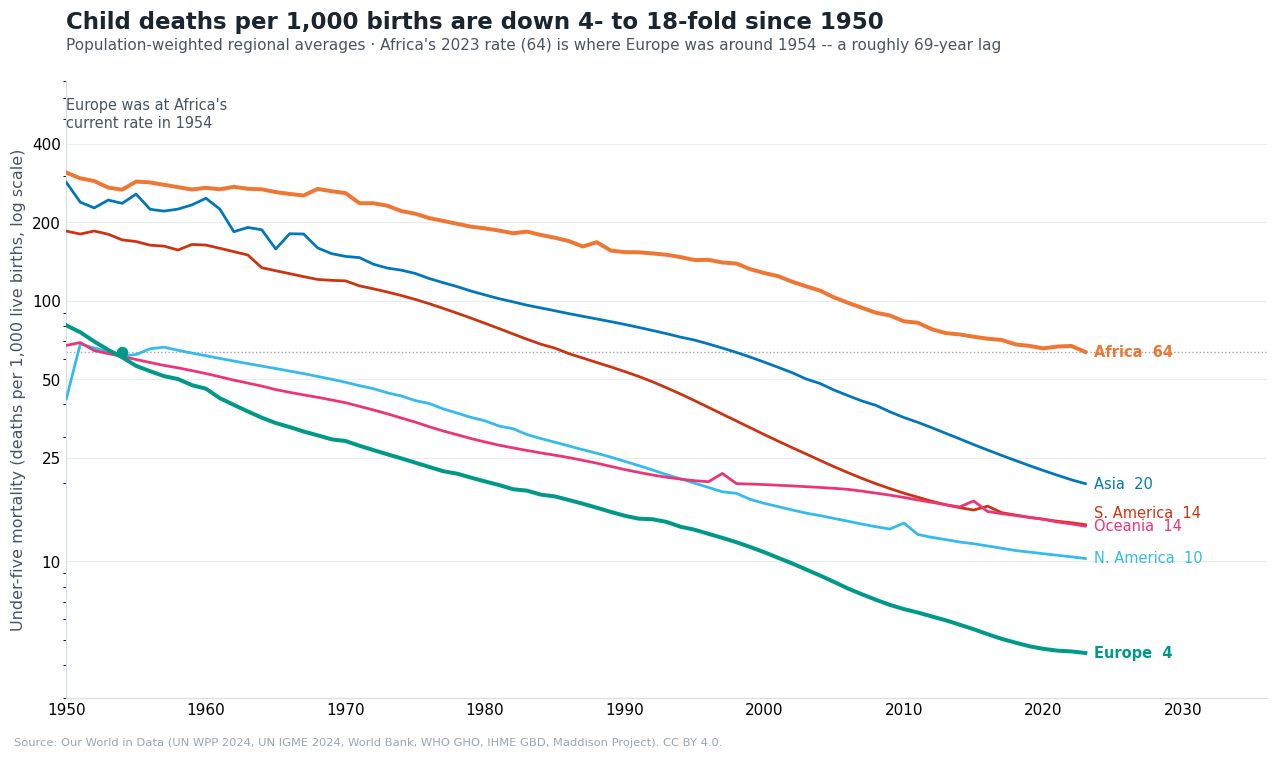

saved ../figures/child_mortality_trends.png


In [2]:
series = regional_series(panel, "child_mortality")
series = series[series["year"].between(1950, 2024)]
piv = series.pivot(index="year", columns="region", values="value")

fig, ax = plt.subplots(figsize=(11.5, 6.8), constrained_layout=True)
entries = []
for region in REGION_COLORS:
    if region not in piv.columns:
        continue
    s = piv[region].dropna()
    emph = region in ("Africa", "Europe")
    ax.plot(s.index, s.values, color=REGION_COLORS[region],
            linewidth=2.6 if emph else 1.8, zorder=4 if emph else 3)
    short = {"North America": "N. America", "South America": "S. America"}.get(region, region)
    entries.append(dict(x=s.index[-1], y=s.iloc[-1], text=f"{short}  {s.iloc[-1]:.0f}",
                        color=REGION_COLORS[region], fontsize=9.6,
                        weight="bold" if emph else "normal"))

# the lag comparison: where was Europe when it had Africa's current rate?
africa_today = piv["Africa"].dropna().iloc[-1]
europe_hist = piv["Europe"].dropna()
europe_match_year = int(europe_hist[europe_hist <= africa_today].index.min())
ax.axhline(africa_today, color=NEUTRAL_LIGHT, linewidth=0.9, linestyle=":", zorder=2)
ax.scatter([europe_match_year], [africa_today], s=42, color="#009988", zorder=5)
# plain text in the empty upper-left corner -- an arrow to the dot would have
# to cross four regional lines to get there
ax.text(1950, 600, f"Europe was at Africa's\ncurrent rate in {europe_match_year}",
        fontsize=9.5, color=NEUTRAL, va="top")

ax.set_yscale("log")
ax.set_ylim(3, 700)
ax.set_yticks([10, 25, 50, 100, 200, 400])
ax.set_yticklabels(["10", "25", "50", "100", "200", "400"])
ax.set_xlim(1950, 2036)
ax.set_ylabel("Under-five mortality (deaths per 1,000 live births, log scale)")
clean_axis(ax)
line_end_labels(ax, entries)
headline(ax, "Child deaths per 1,000 births are down 4- to 18-fold since 1950",
         f"Population-weighted regional averages · Africa's 2023 rate ({africa_today:.0f}) is where "
         f"Europe was around {europe_match_year} -- a roughly {2023 - europe_match_year}-year lag")
save(fig, "child_mortality_trends")

In [3]:
piv.loc[[1950, 1990, 2023]].round(1)

region,Africa,Asia,Europe,North America,Oceania,South America
year,,,,,,
1950,310.2,284.5,80.5,42.1,67.4,185.1
1990,153.6,81.1,15.0,24.2,22.5,53.5
2023,63.6,19.9,4.5,10.3,13.6,13.8


The steepest gradient in global health, in one chart:

- **Every region fell between 4- and 18-fold.** Europe: 80 → 4.5 (18×). South America: 185 → 14. Asia: 284 → 20. Africa: 310 → 64 — the smallest multiple, from the worst start, with the HIV/AIDS era visible as the flat stretch of Africa's line in the 1990s. (North America and Oceania "only" fell ~4–5× because they were already in the 40s–60s in 1950.) The world aggregate went from 247 to 38 per 1,000 between 1950 and 2023.
- **The uncomfortable framing**: Africa's current rate is where **Europe stood in 1954** — a ~69-year lag at current rates.
- Is the lag closing? In **absolute** terms, yes: the Africa–Europe gap fell from ~230 to ~59 per 1,000. In **pace** terms, not yet: Africa is improving at about 3% a year (since 2000), while Europe at the same level in the 1950s halved its rate in 13 years (−5%/yr). At current rates Africa needs roughly two decades just to halve from here.
- The country-level view (map in geographic_analysis.ipynb) is more pointed still: nearly every country above 50 per 1,000 is in the Sahel and equatorial Africa. Nigeria — the fifth-largest country by population — combines some of the weakest outcomes with the largest cohort of children at risk, which makes it the single most consequential case in this indicator.

## 2. Water, sanitation, and child survival

Two scatter panels: under-five mortality (log scale) against improved drinking-water access and improved-sanitation access, both at their latest vintage. The smooth line is **LOWESS** — local regression, no functional form imposed — because there's no reason to believe the relationship is a straight line in anything. Spearman's rank correlation is the honest summary statistic when a relationship is monotone but strongly non-linear.

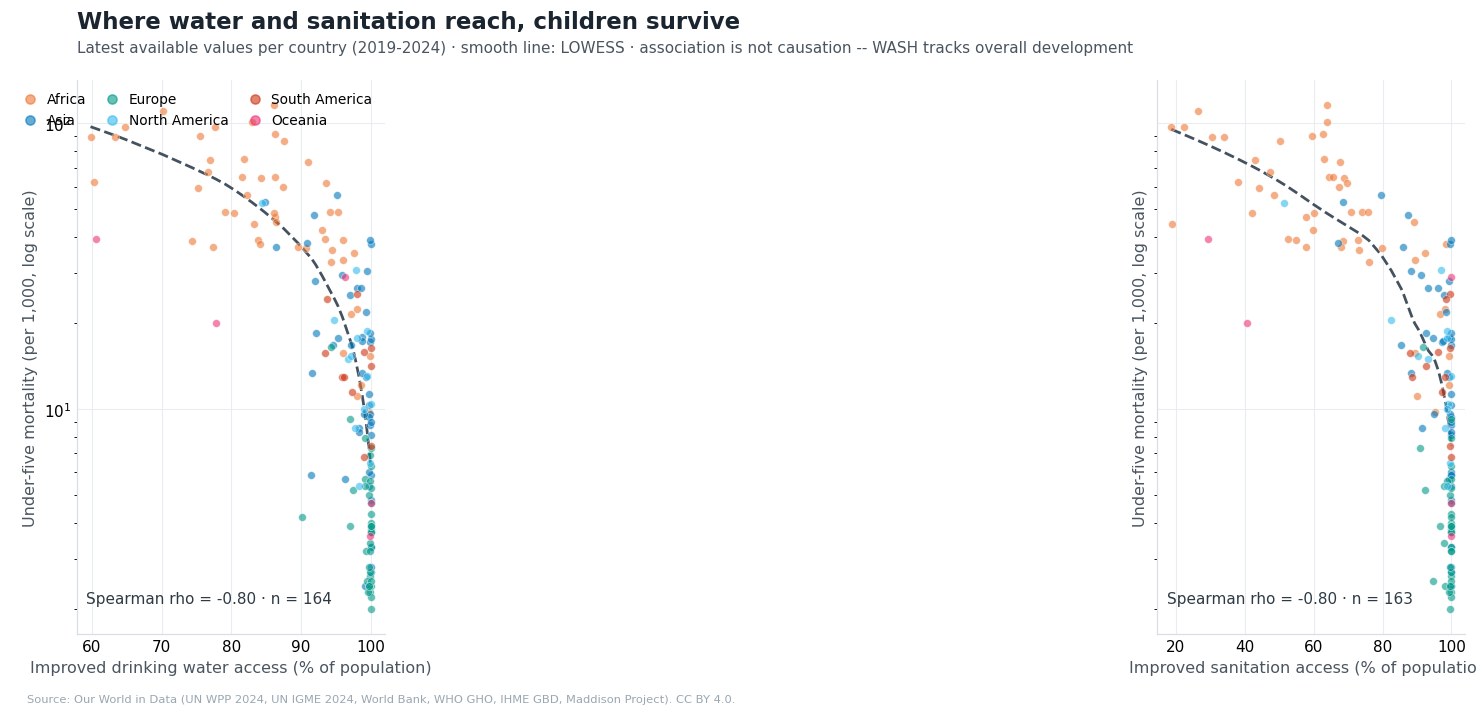

saved ../figures/wash_vs_child_mortality.png


In [4]:
snap = snapshot_multi(panel, ["child_mortality", "water_access", "sanitation_access"],
                      window=5, min_pop_k=500)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 6.4), sharey=True, constrained_layout=True)
panels = [
    ("water_access", "Improved drinking water access (% of population)"),
    ("sanitation_access", "Improved sanitation access (% of population)"),
]
for ax, (key, xlabel) in zip(axes, panels):
    d = snap.dropna(subset=[key, "child_mortality"])
    for region, colour in REGION_COLORS.items():
        chunk = d[d["region"] == region]
        if not chunk.empty:
            ax.scatter(chunk[key], chunk["child_mortality"], s=26, color=colour,
                       alpha=0.6, edgecolors="white", linewidths=0.4, zorder=3)
    sns.regplot(data=d, x=key, y="child_mortality", ax=ax, scatter=False,
                lowess=True, line_kws=dict(color="#44525F", linewidth=1.8, ls="--"))
    rho = stats.spearmanr(d[key], d["child_mortality"]).statistic
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Under-five mortality (per 1,000, log scale)")
    # bottom-left corner is guaranteed empty on these panels: no country has
    # low WASH coverage AND low child mortality
    ax.annotate(f"Spearman rho = {rho:.2f} · n = {len(d)}",
                xy=(0.03, 0.05), xycoords="axes fraction", va="bottom",
                fontsize=10, color="#2E3A44")
    clean_axis(ax, grid=True, axis="both")

# the scatters above weren't given labels, so build the legend from proxies;
# one row, tucked into the top-right where no countries sit
axes[0].legend([plt.Line2D([], [], marker="o", ls="", color=c, alpha=0.6)
                for c in REGION_COLORS.values()],
               list(REGION_COLORS), loc="upper right", ncol=3, fontsize=9,
               columnspacing=0.9, handletextpad=0.2)
headline(axes[0], "Where water and sanitation reach, children survive",
         "Latest available values per country (2019-2024) · smooth line: LOWESS · "
         "association is not causation -- WASH tracks overall development")
save(fig, "wash_vs_child_mortality")

Both relationships are strong — Spearman ρ ≈ **−0.80** for water and for sanitation against under-five mortality — and both have the same *shape*, which is the more interesting part: steep below roughly 80% coverage, then flattening as access approaches universal. Consistent with the pattern that the marginal child protected by the first latrine in a village is much easier to reach than the last one, though a cross-sectional curve can't prove that mechanism — it can only be consistent with it.

Remember what's being correlated, though: "improved" water/sanitation (a service-*type* classification from the JMP, not a water-quality measurement) and a mortality rate that also depends on nutrition, disease environment, and the health system. WASH moves with all of them.

## 3. Routine immunization

DTP3 — three doses of the diphtheria-tetanus-pertussis vaccine by age one — is the WHO's standard probe for whether a routine immunization system actually reaches children. Bubble area is population; the log-scale y-axis is child mortality.

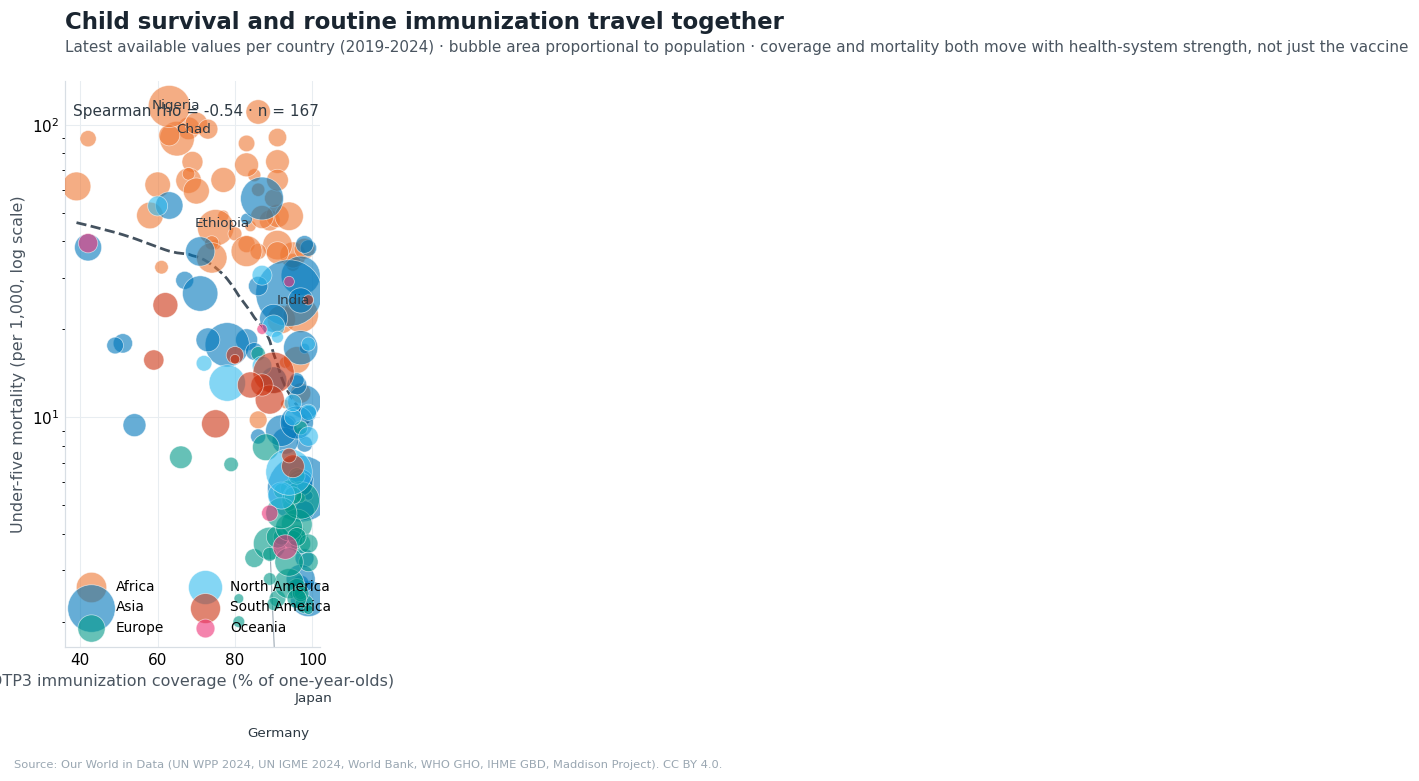

saved ../figures/dtp3_vs_child_mortality.png


In [5]:
from adjustText import adjust_text

snap = (snapshot_multi(panel, ["child_mortality", "dtp3", "population"],
                       window=5, min_pop_k=500)
        .dropna(subset=["dtp3", "child_mortality"]))

fig, ax = plt.subplots(figsize=(10.8, 7.0), constrained_layout=True)
for region, colour in REGION_COLORS.items():
    chunk = snap[snap["region"] == region]
    if not chunk.empty:
        sizes = np.sqrt(chunk["population"].fillna(1e6)) / 20.0
        ax.scatter(chunk["dtp3"], chunk["child_mortality"], s=sizes, color=colour,
                   alpha=0.6, edgecolors="white", linewidths=0.5, label=region, zorder=3)
sns.regplot(data=snap, x="dtp3", y="child_mortality", ax=ax, scatter=False,
            lowess=True, line_kws=dict(color="#44525F", linewidth=1.8, ls="--"))

# label a few countries; adjustText keeps the labels off the bubbles
texts = []
for country in ["Nigeria", "India", "Chad", "Japan", "Germany", "Ethiopia"]:
    row = snap[snap["country"] == country]
    if not row.empty:
        texts.append(ax.text(row["dtp3"].iloc[0], row["child_mortality"].iloc[0],
                             country, fontsize=8.8, color="#2E3A44"))
pts = snap[["dtp3", "child_mortality"]]
adjust_text(texts, ax=ax, x=list(pts["dtp3"]), y=list(pts["child_mortality"]),
            arrowprops=dict(arrowstyle="-", color=NEUTRAL_LIGHT, lw=0.7),
            force_text=(0.6, 0.9), force_static=(0.35, 0.55), expand=(1.15, 1.3))

rho = stats.spearmanr(snap["dtp3"], snap["child_mortality"]).statistic
ax.set_yscale("log")
ax.set_xlabel("DTP3 immunization coverage (% of one-year-olds)")
ax.set_ylabel("Under-five mortality (per 1,000, log scale)")
ax.annotate(f"Spearman rho = {rho:.2f} · n = {len(snap)}",
            xy=(0.03, 0.96), xycoords="axes fraction", va="top",
            fontsize=10, color="#2E3A44")
# the lower-left corner is empty on this chart (low coverage with low
# mortality does not exist), so the legend lives there
ax.legend(loc="lower left", ncol=2, fontsize=9)
clean_axis(ax, grid=True, axis="both")
headline(ax, "Child survival and routine immunization travel together",
         "Latest available values per country (2019-2024) · bubble area proportional to population · "
         "coverage and mortality both move with health-system strength, not just the vaccine")
save(fig, "dtp3_vs_child_mortality")

ρ ≈ **−0.54** — strong, but weaker than WASH, and the chart explains why: look at the empty lower-left corner. There is no country with low DTP3 coverage *and* low child mortality, but there are countries with high coverage and middling mortality (Brazil, India at the top of the coverage range). Coverage looks like a floor condition — necessary-ish, far from sufficient.

To say the obvious once more, because this chart invites the wrong reading more than any other in the project: **this is not an estimate of the vaccine's effect on mortality.** DTP3 coverage measures whether a system can deliver three touches of healthcare to an infant; countries that can, also deliver the rest of the package — maternity care, antibiotics, nutrition. The scatter shows the package, not the product.

## Recap

Child mortality is the fastest-improving and most unequal indicator in this project: 4- to 18-fold regional declines since 1950, with the remaining burden concentrated in one contiguous belt of Africa. WASH and immunization correlate strongly with survival, in the direction everyone expects, with shapes (steep then flat; empty corners) that are more informative than the correlation coefficients themselves.

Next: **[socioeconomic_links.ipynb](socioeconomic_links.ipynb)** — income, spending, and the correlation matrix that carries its own warning label.